<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_29_Hidden_State_Dimensionality_Reduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.gridspec import GridSpec

from PIL import Image
import requests
from io import BytesIO

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

# Part_1:Reducing Dimension while preserving shape

## Task_1:
- Use the online code to import the picture of the Stedelijk Museum
in Amsterdam and convert it to grayscale.
Calculate the SVD and visualize the three matrices and the
scree plot (scatter plot of sorted singular values) as shown in Figure
5.32

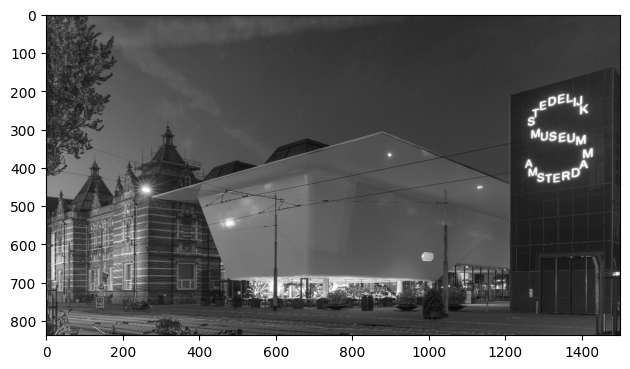

In [22]:

# url = 'https://upload.wikimedia.org/wikipedia/commons/6/61/De_nieuwe_vleugel_van_het_Stedelijk_Museum_Amsterdam.jpg'
url = 'https://sincxpress.com/De_nieuwe_vleugel_van_het_Stedelijk_Museum_Amsterdam.jpg'

response = requests.get(url,headers={'User-Agent':'Mozilla/5.0 (compatible; ImageLoader/1.0)'})
img = Image.open(BytesIO(response.content))

# convert to grayscale and numpy
img = np.array( img.convert('L') ,dtype=float)
img = img[::2,::2] # downsample

plt.imshow(img,cmap='gray')

plt.tight_layout()
plt.show()

In [23]:
# img1 = img[::2,::2]
# plt.imshow(img1,cmap='gray')
# plt.tight_layout()
# plt.show()

In [24]:
# img2 = img[::4,::4]
# plt.imshow(img2,cmap='gray')
# plt.tight_layout()
# plt.show()

In [25]:
# img3 = img[::6,::6]
# plt.imshow(img3,cmap='gray')
# plt.tight_layout()
# plt.show()

In [26]:
# img4 = img[::8,::8]
# plt.imshow(img4,cmap='gray')
# plt.tight_layout()
# plt.show()

In [27]:
# img5 = img[::10,::10]
# plt.imshow(img5,cmap='gray')
# plt.tight_layout()
# plt.show()

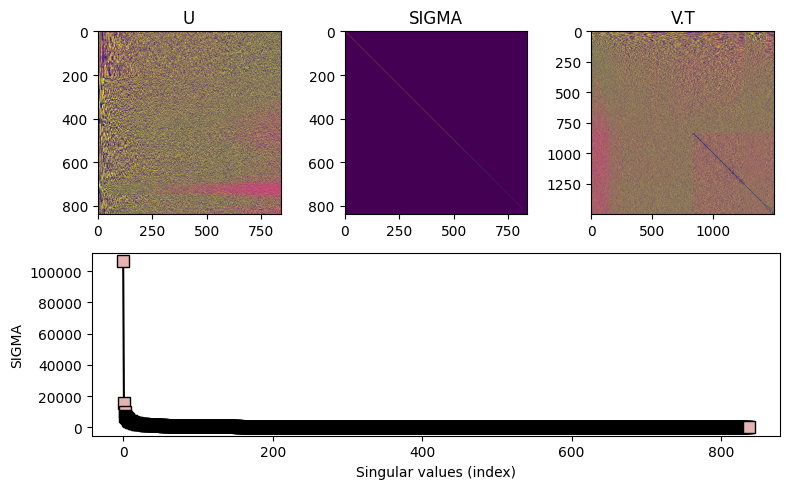

In [28]:


# SVD
U,s,Vh = np.linalg.svd(img)


# visualize
fig = plt.figure(figsize=(8,5))
gs = GridSpec(2,3,figure=fig)
ax1 = fig.add_subplot(gs[0,0])
ax2 = fig.add_subplot(gs[0,1])
ax3 = fig.add_subplot(gs[0,2])
ax4 = fig.add_subplot(gs[1,:])

ax1.imshow(U,vmin=-.01,vmax=.01,cmap='plasma')
ax1.set(title='U')

ax2.imshow(np.diag(s),vmin=0,vmax=200)
ax2.set(title='SIGMA')

ax3.imshow(Vh,vmin=-.01,vmax=.01,cmap='plasma')
ax3.set(title='V.T')

ax4.plot(s,'ks-',markerfacecolor=[.9,.7,.7],markersize=8)
ax4.set(xlabel='Singular values (index)',ylabel='SIGMA')

plt.tight_layout()
plt.show()


## Task_2:
- Transform the singular values to percent variance explained (as a
reminder: pcti = 100σ2
i/ σ2). Create a low-rank reconstruction
of the image by applying Equation 5.7 with r = 50. Calculate the
percent variance explained using those 50 components, and visualize
the original and reconstructed images as in Figure 5.33.

In [32]:
img.shape

(838, 1500)

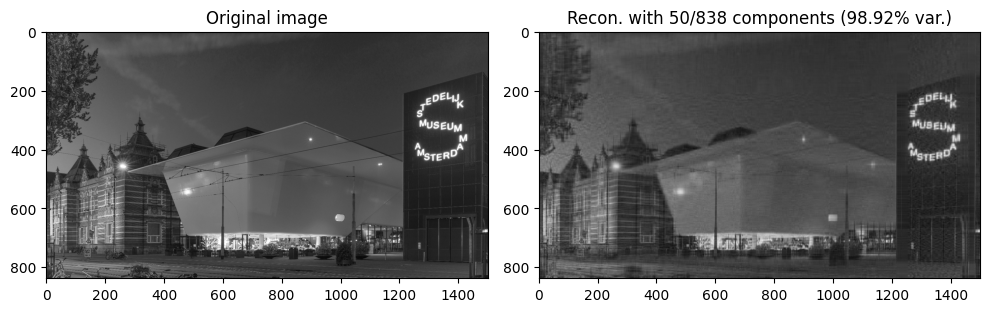

In [34]:

# convert to cumulative percent
pct = 100 * s**2/np.sum(s**2)
cum_pct =np.cumsum(pct)


# components to keep
comps2keep = 50
S = np.zeros_like(img)
for i in range(comps2keep):
  S[i,i]=s[i]

# reconstruct the matrix
recon_img1 =U @ S @ Vh


_,axs = plt.subplots(1,2,figsize=(10,4))
axs[0].imshow(img,cmap='gray')
axs[0].set(title='Original image')

axs[1].imshow(recon_img1,cmap='gray')
axs[1].set(title=f'Recon. with {comps2keep}/{len(s)} components ({cum_pct[comps2keep]:.2f}% var.)')

plt.tight_layout()
plt.show()

## Task_3:
- Repeat the reconstruction, but now choose r as the number of
components that explains 98% of the image variance. If you used
my for-loop code to create the Σ matrix, then try to solve it this
time without a for-loop (hint: use slicing to copy a square diagonal
matrix into part of a non-square zeros matrix).
Calculate and report the ranks of the original and two recon
structed matrices.

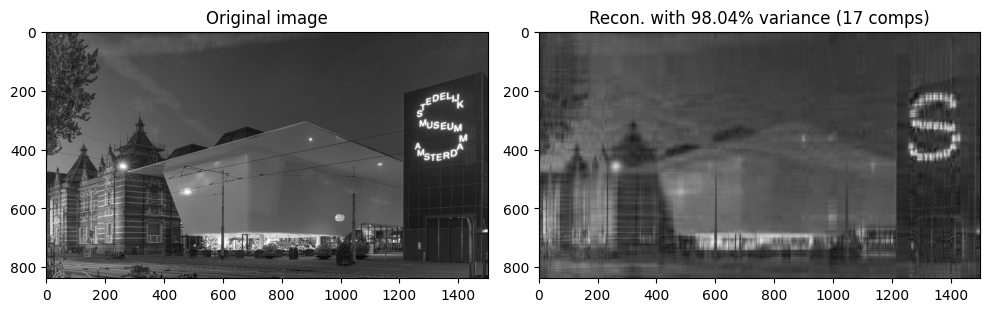

In [41]:
# percent variance to keep
thresh = 98
r = np.where(cum_pct>=thresh)[0][0]

# loopless method
S = np.zeros_like(img)
S[:r,:r] =np.diag(s[:r])

# reconstruction
recon_img2 =U @ S @ Vh

_,axs = plt.subplots(1,2,figsize=(10,4))
axs[0].imshow(img,cmap='gray')
axs[0].set(title='Original image')

axs[1].imshow(recon_img2,cmap='gray')
axs[1].set(title=f'Recon. with {cum_pct[r]:.2f}% variance ({r} comps)')

plt.tight_layout()

plt.show()


In [42]:


print(f'Rank of original matrix: {np.linalg.matrix_rank(img)}')
print(f'Rank of r = 50 matrix  : {np.linalg.matrix_rank(recon_img1)}')
print(f'Rank of p = {thresh}% matrix : {np.linalg.matrix_rank(recon_img2)}')


Rank of original matrix: 838
Rank of r = 50 matrix  : 50
Rank of p = 98% matrix : 17


# Part 2: Dimension-reduce one hidden state

## Task_1:
- Import the Eleuther GPT-neo-1.3b LLM and its tokenizer (available
from Hugging Face with EleutherAI/gpt-neo-1.3b). Move it to
the GPU if you have one available.
The online code file contains some text about the Stedelijk
Museum copied from its Wikipedia page. Run the tokens through
the model and collect the hidden-state vectors. Name the model
output variable outs_clean for comparison with the manipulated
model in the next part.
Extract the hidden-state vectors from one layer (I used layer
4). Calculate a vector of the column means, a vector of the row
means, and a scalar of the global mean (across all matrix elements).
Broadcast-subtract both the column and row means vectors, and
then add back the global matrix mean. Show the SVD matrices and
scree plot as in Figure 5.34.

In [47]:
device=torch.device('cuda:0' if torch.cuda.is_available() else "cpu")

In [48]:
device

device(type='cuda', index=0)

In [49]:
tokenizer = AutoTokenizer.from_pretrained('EleutherAI/gpt-neo-1.3b')
model = AutoModelForCausalLM.from_pretrained('EleutherAI/gpt-neo-1.3b') # can use '125m' instead of '1.3b'
model.eval()
model.to(device)

config.json:   0%|          | 0.00/1.35k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/90.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.31GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/316 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-1.3b
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
transformer.h.{0...23}.attn.attention.masked_bias | UNEXPECTED |  | 
transformer.h.{0...22}.attn.attention.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


GPTNeoForCausalLM(
  (transformer): GPTNeoModel(
    (wte): Embedding(50257, 2048)
    (wpe): Embedding(2048, 2048)
    (drop): Dropout(p=0.0, inplace=False)
    (h): ModuleList(
      (0-23): 24 x GPTNeoBlock(
        (ln_1): LayerNorm((2048,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPTNeoAttention(
          (attention): GPTNeoSelfAttention(
            (attn_dropout): Dropout(p=0.0, inplace=False)
            (resid_dropout): Dropout(p=0.0, inplace=False)
            (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
            (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
            (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
            (out_proj): Linear(in_features=2048, out_features=2048, bias=True)
          )
        )
        (ln_2): LayerNorm((2048,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPTNeoMLP(
          (c_fc): Linear(in_features=2048, out_features=8192, bias=Tru

In [51]:
model.config

GPTNeoConfig {
  "activation_function": "gelu_new",
  "architectures": [
    "GPTNeoForCausalLM"
  ],
  "attention_dropout": 0,
  "attention_layers": [
    "global",
    "local",
    "global",
    "local",
    "global",
    "local",
    "global",
    "local",
    "global",
    "local",
    "global",
    "local",
    "global",
    "local",
    "global",
    "local",
    "global",
    "local",
    "global",
    "local",
    "global",
    "local",
    "global",
    "local"
  ],
  "attention_types": [
    [
      [
        "global",
        "local"
      ],
      12
    ]
  ],
  "bos_token_id": 50256,
  "classifier_dropout": 0.1,
  "dtype": "float32",
  "embed_dropout": 0,
  "eos_token_id": 50256,
  "gradient_checkpointing": false,
  "hidden_size": 2048,
  "initializer_range": 0.02,
  "intermediate_size": null,
  "layer_norm_epsilon": 1e-05,
  "max_position_embeddings": 2048,
  "model_type": "gpt_neo",
  "num_heads": 16,
  "num_layers": 24,
  "pad_token_id": null,
  "resid_dropout": 0,
  "

In [50]:
text = 'The Stedelijk Museum Amsterdam (Dutch pronunciation: [ˈsteːdələk myˈzeːjʏm ˌɑmstərˈdɑm]; Municipal Museum Amsterdam), colloquially known as the Stedelijk, is a museum for modern art, contemporary art, and design located in Amsterdam, Netherlands.[6] The 19th-century building was designed by Adriaan Willem Weissman. The connecting 21st-century wing, which houses the current entrance, was designed by Benthem Crouwel Architects. The museum is located at the Museum Square in the borough Amsterdam South,[2] where it is close to the Van Gogh Museum, the Rijksmuseum, and the Concertgebouw.'
tokens = tokenizer.encode(text,return_tensors='pt').to(device)

# clean run
layer2reduce = 4000
with torch.no_grad():
  outs_clean = model(tokens,output_hidden_states=True)

outs_clean.hidden_states[0].shape

torch.Size([1, 167, 2048])

In [66]:
h=torch.tensor([[2,2],[3,3]],dtype=float)
h.mean(dim=0,keepdims=True)

tensor([[2.5000, 2.5000]], dtype=torch.float64)

In [68]:
h.mean(dim=1)

tensor([2., 3.], dtype=torch.float64)

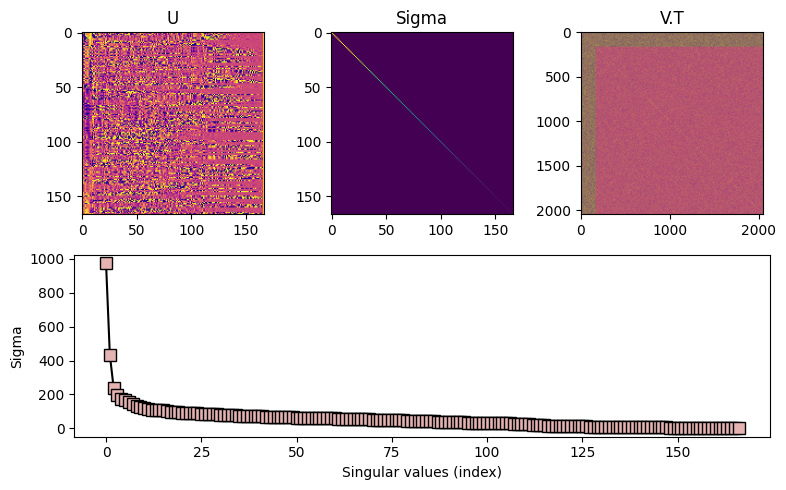

In [72]:

hs = outs_clean.hidden_states[4][0,:,:].cpu()

# SVD of mean-centered data
vectmeans0 = hs.mean(dim=0,keepdims=True)
vectmeans1 = hs.mean(dim=1,keepdims=True)
globalmean = hs.mean()
hs_demean = hs - vectmeans0 - vectmeans1 + globalmean
U,s,Vh =torch.linalg.svd(hs_demean)

fig = plt.figure(figsize=(8,5))
gs = GridSpec(2,3,figure=fig)
ax1 = fig.add_subplot(gs[0,0])
ax2 = fig.add_subplot(gs[0,1])
ax3 = fig.add_subplot(gs[0,2])
ax4 = fig.add_subplot(gs[1,:])

ax1.imshow(U,vmin=-.1,vmax=.1,cmap='plasma')
ax1.set(title='U')

ax2.imshow(torch.diag(s),vmin=0,vmax=100)
ax2.set(title='Sigma')

ax3.imshow(Vh,vmin=-.01,vmax=.01,cmap='plasma')
ax3.set(title='V.T')

ax4.plot(s,'ks-',markerfacecolor=[.9,.7,.7],markersize=8)
ax4.set(xlabel='Singular values (index)',ylabel='Sigma')

plt.tight_layout()
plt.show()


## Task_2:
- Reduce the dimensionality of the hidden state matrix to r di
mensions, where r is the number of components to explain 95%
of the variance. You can copy the reconstruction code from the
image demo in Part 1, but (1) translate the NumPy functions to
PyTorch and (2) add both dimensional means back onto the recon
structed hidden-state vectors, and subtract the global mean. Confirm
that the shapes of the original and reconstructed hidden states match.
Visualize both hidden-state matrices, their difference, and their
correlation as in Figure 5.35. Use the same color limits for all
three heatmaps. Calculate and report the ranks of the original and
reconstructed matrices

In [79]:

# reduction threshold
svd_thresh = 95

# find number of components to threshold
cum_pct = torch.cumsum(100*s**2/torch.sum(s**2),dim=-1)
r = torch.where(cum_pct>svd_thresh)[0][0]

# create a new Sigma matrix
S = torch.zeros(hs.shape)
S[:r,:r] = torch.diag(s[:r])

# reconstruct data (with means added back)
hs_R = U@S@Vh + vectmeans0 + vectmeans1 - globalmean

print('hidden state shape:\n ',hs.shape,'\n')
print('reconstruction shape:\n ',hs_R.shape)

hidden state shape:
  torch.Size([167, 2048]) 

reconstruction shape:
  torch.Size([167, 2048])


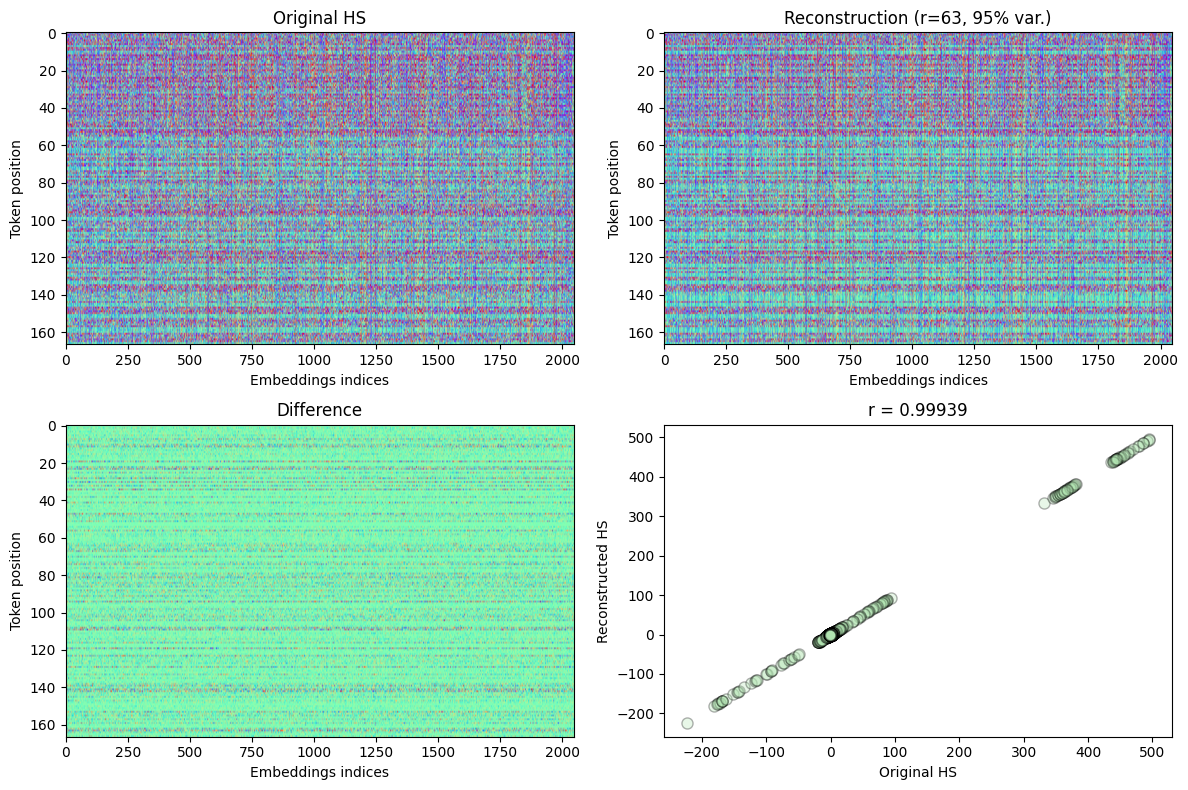

In [80]:

# visualize
_,axs = plt.subplots(2,2,figsize=(12,8))

axs[0,0].imshow(hs,aspect='auto',vmin=-2,vmax=2,cmap='rainbow')
axs[0,0].set(xlabel='Embeddings indices',ylabel='Token position',title='Original HS')

axs[0,1].imshow(hs_R,aspect='auto',vmin=-2,vmax=2,cmap='rainbow')
axs[0,1].set(xlabel='Embeddings indices',ylabel='Token position',title=f'Reconstruction (r={r}, {svd_thresh}% var.)')

axs[1,0].imshow(hs-hs_R,aspect='auto',vmin=-2,vmax=2,cmap='rainbow')
axs[1,0].set(xlabel='Embeddings indices',ylabel='Token position',title='Difference')

axs[1,1].plot(hs.flatten()[::10],hs_R.flatten()[::10],'ko',markersize=8,markerfacecolor=[.7,.9,.7,.3])
axs[1,1].set(xlabel='Original HS',ylabel='Reconstructed HS',
              title=f'r = {np.corrcoef(hs.flatten(),hs_R.flatten())[0,1]:.5f}')

plt.tight_layout()
plt.show()

In [81]:

print(f'Rank of original hidden-state matrix: {torch.linalg.matrix_rank(hs)}')
print(f'Rank of reduced hidden-state matrix : {torch.linalg.matrix_rank(hs_R):3}')

Rank of original hidden-state matrix: 166
Rank of reduced hidden-state matrix :  65


# Part 3: A hook to reduce hidden state dimensionality

## Task_1:
- Create and implant a hook function into all transformer layers. The
goal of the hook function is to replace the hidden states of one layer
with an SVD-reduced version of the hidden states. Choose the rank
r that explains 99% of the variance. (Hint: integrate code from
Project 27 with code from Part 2 in this project.)
Also store the number of components it takes to capture 99%
of the variance. Have the hook function print a summary like this:
for each layer.
Changed layer 4 with 99.03% variance (106/167 comps)
Test the hook function by reducing one layer during a forward
pass with the same tokens you used earlier in this project. Compare
the matrix norm of the hidden-state differences between the recon
structed

In [82]:
len(outs_clean.hidden_states)

25

In [84]:
svd_thresh = 99 # %
layer2reduce = 4
compsCount = []

# hooking functions
def implant_hook(layer_number):
  def hook(module, input, hidden):

    # only change one layer
    if layer_number == layer2reduce:

      # extract hidden state and mean-center
      if isinstance(hidden,tuple):
        hs = hidden[0].detach()[0,:,:]
      else:
        hs = hidden[0,:,:].detach()

      vectmeans0 =hs.mean(dim=0,keepdims=True)
      vectmeans1 =hs.mean(dim=1,keepdims=True)
      globalmean =hs.mean()
      hs_demean =hs-vectmeans0- vectmeans1 +globalmean

      # SVD
      U,s,Vh = torch.linalg.svd(hs_demean)

      # find number of components to threshold
      cum_pct = torch.cumsum(100* s **2/torch.sum(s**2),dim=-1)
      r =torch.where(cum_pct>thresh)[0][0]
      compsCount.append(r.item()) # update count (back on the cpu)

      # create a new Sigma matrix
      S = torch.zeros(hs.shape,device=hs[0].device)
      S[:r,:r] =torch.diag(s[:r])

      # print some info
      print(f'Changed layer {layer_number:2} with {cum_pct[r]:.2f}% variance ({r:2}/{len(s)} comps)')

      # reconstruct data (with means added back)
      hidden_copy = hidden[0].clone() # make a copy
      hidden_copy[0,:,:] = U@S@Vh + vectmeans0 + vectmeans1  - globalmean
      hidden = tuple([hidden_copy])

    return hidden
  return hook


# loop over layers and do surgery
handles = []
for layeri in range(model.config.num_layers):
  baselayer = model.transformer.h[layeri]
  h = baselayer.register_forward_hook(implant_hook(layeri))
  handles.append(h)

In [83]:
model.config.num_layers

24

In [85]:

# with reduction
layer2reduce = 4
with torch.no_grad():
  outs_reduced = model(tokens,output_hidden_states=True)

outs_reduced.hidden_states[0].shape

Changed layer  4 with 98.04% variance (90/167 comps)


torch.Size([1, 167, 2048])

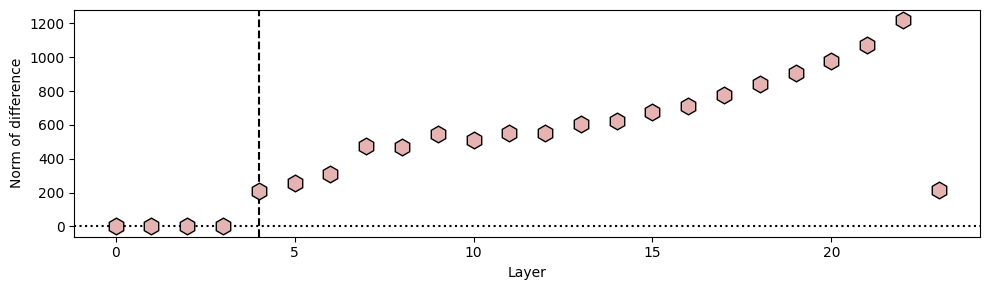

In [86]:

# initialize
diffnorms = torch.zeros(model.config.num_layers)

# loop over layers
for layeri in range(model.config.num_layers):

  # extract hidden states for this layer
  hs_c = outs_clean.hidden_states[layeri+1]
  hs_n = outs_reduced.hidden_states[layeri+1]

  # norm of difference matrix
  diffnorms[layeri] = torch.norm(hs_c-hs_n).cpu()

# and plot
plt.figure(figsize=(10,3))
plt.plot(diffnorms,'kh',markerfacecolor=[.9,.7,.7],markersize=12)
plt.axvline(layer2reduce,color='k',linestyle='--',zorder=-3)
plt.axhline(0,color='k',linestyle=':',zorder=-10)
plt.gca().set(xlabel='Layer',ylabel='Norm of difference')

plt.tight_layout()
plt.show()